In [ ]:
%pip install matplotlib seaborn numpy pandas torch datasets transformers

In [56]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import time
import copy
import gc

import matplotlib.pyplot as plt
import seaborn as sns
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from datasets import load_dataset
from transformers import AutoTokenizer, LlamaTokenizer

In [34]:
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

---
# Utils

## Loaders

In [35]:
DEV = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')

def get_opt(model):
    def skip(*args, **kwargs):
        pass
    torch.nn.init.kaiming_uniform_ = skip
    torch.nn.init.uniform_ = skip
    torch.nn.init.normal_ = skip
    from transformers import AutoModelForCausalLM
    model = AutoModelForCausalLM.from_pretrained(model, torch_dtype='auto')
    model.seqlen = model.config.max_position_embeddings
    return model

def set_seed(seed):
    np.random.seed(seed)
    torch.random.manual_seed(seed)

def get_tokenizer(model):
    if "llama" in model.lower() and "llama-3" not in model.lower():
        tokenizer = LlamaTokenizer.from_pretrained(model, use_fast=False)
        # fix for transformer 4.28.0.dev0 compatibility
        if tokenizer.bos_token_id != 1 or tokenizer.eos_token_id != 2:
            try:
                tokenizer.bos_token_id = 1
                tokenizer.eos_token_id = 2
            except AttributeError:
                pass
    else:
        tokenizer = AutoTokenizer.from_pretrained(model, use_fast=False)
    return tokenizer

def get_wikitext2(nsamples, seed, seqlen, model, tokenizer):

    traindata = load_dataset('wikitext', 'wikitext-2-raw-v1', split='train')
    testdata = load_dataset('wikitext', 'wikitext-2-raw-v1', split='test')

    trainenc = tokenizer(" ".join(traindata['text']), return_tensors='pt')
    testenc = tokenizer("\n\n".join(testdata['text']), return_tensors='pt')
    print("ts", trainenc.input_ids.shape)

    random.seed(seed)
    trainloader = []
    if False:
        for _ in range(nsamples):
            i = random.randint(0, trainenc.input_ids.shape[1] - seqlen - 1)
            j = i + seqlen
            inp = trainenc.input_ids[:, i:j]
            tar = inp.clone()
            tar[:, :-1] = -100
            trainloader.append((inp, tar))
    else:
        i = 0
        for _ in range(nsamples):
#            i = random.randint(0, trainenc.input_ids.shape[1] - seqlen - 1)
            j = i + seqlen
            inp = trainenc.input_ids[:, i:j]
            tar = inp.clone()
            tar[:, :-1] = -100
            trainloader.append((inp, tar))
            i = j
    return trainloader, testenc

def get_ptb(nsamples, seed, seqlen, model, tokenizer):
    traindata = load_dataset('ptb_text_only', 'penn_treebank', split='train')
    testdata = load_dataset('ptb_text_only', 'penn_treebank', split='test')

    trainenc = tokenizer(" ".join(traindata['sentence']), return_tensors='pt')
    testenc = tokenizer(" ".join(testdata['sentence']), return_tensors='pt')

    random.seed(seed)
    trainloader = []
    for _ in range(nsamples):
        i = random.randint(0, trainenc.input_ids.shape[1] - seqlen - 1)
        j = i + seqlen
        inp = trainenc.input_ids[:, i:j]
        tar = inp.clone()
        tar[:, :-1] = -100
        trainloader.append((inp, tar))
    return trainloader, testenc

def get_c4(nsamples, seed, seqlen, model, tokenizer):
    traindata = load_dataset(
        'allenai/c4', data_files={'train': 'en/c4-train.00000-of-01024.json.gz'}, split='train'
    )
    valdata = load_dataset(
        'allenai/c4', data_files={'validation': 'en/c4-validation.00000-of-00008.json.gz'}, split='validation'
    )

    random.seed(seed)
    trainloader = []
    for _ in range(nsamples):
        while True:
            i = random.randint(0, len(traindata) - 1)
            trainenc = tokenizer(traindata[i]['text'], return_tensors='pt')
            if trainenc.input_ids.shape[1] > seqlen:
                break
        i = random.randint(0, trainenc.input_ids.shape[1] - seqlen - 1)
        j = i + seqlen
        inp = trainenc.input_ids[:, i:j]
        tar = inp.clone()
        tar[:, :-1] = -100
        trainloader.append((inp, tar))

    valenc = tokenizer(' '.join(valdata[:1100]['text']), return_tensors='pt')
    valenc = valenc.input_ids[:, :(256 * seqlen)]

    class TokenizerWrapper:
        def __init__(self, input_ids):
            self.input_ids = input_ids
    valenc = TokenizerWrapper(valenc)

    return trainloader, valenc

def get_loaders(name, nsamples=128, seed=0, seqlen=2048, model=''):
    tokenizer = get_tokenizer(model)
    if 'wikitext2' in name:
        return get_wikitext2(nsamples, seed, seqlen, model, tokenizer)
    if 'ptb' in name:
        return get_ptb(nsamples, seed, seqlen, model, tokenizer)
    if 'c4' in name:
        return get_c4(nsamples, seed, seqlen, model, tokenizer)

## Evaluation

In [36]:
@torch.no_grad()
def eval_ppl(model, testenc, bs=1, device=None):
    # Get input IDs
    testenc = testenc.input_ids

    # Calculate number of samples
    nsamples = testenc.numel() // model.seqlen
    # nsamples = 10
    # List to store negative log likelihoods
    nlls = []

    # Loop through each batch
    for i in range(0,nsamples,bs):
        # Calculate end index
        j = min(i+bs, nsamples)

        # Prepare inputs and move to device
        inputs = testenc[:,(i * model.seqlen):(j * model.seqlen)].to(device)
        inputs = inputs.reshape(j-i, model.seqlen)

        # Forward pass through the model
        lm_logits = model(inputs).logits

        # Shift logits and labels for next token prediction
        shift_logits = lm_logits[:, :-1, :].contiguous()
        shift_labels = inputs[:, 1:]

        # Compute loss
        loss_fct = nn.CrossEntropyLoss()
        loss = loss_fct(shift_logits.reshape(-1, shift_logits.size(-1)), shift_labels.reshape(-1))

        # Calculate negative log likelihood
        neg_log_likelihood = loss.float() * model.seqlen * (j-i)

        # Append to list of negative log likelihoods
        nlls.append(neg_log_likelihood)

    # Compute perplexity
    ppl = torch.exp(torch.stack(nlls).sum() / (nsamples * model.seqlen))

    # Empty CUDA cache to save memory
    torch.cuda.empty_cache()

    return ppl.item()

# Load

## Model

In [37]:
# model_name = "HuggingFaceTB/SmolLM2-135M"
model_name = "HuggingFaceTB/SmolLM2-1.7B"

model = get_opt(model_name)
model.eval()
model.to(DEV)

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(49152, 2048)
    (layers): ModuleList(
      (0-23): 24 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (k_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (v_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (up_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (down_proj): Linear(in_features=8192, out_features=2048, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((2048,), eps=1e-05)
    (rotary_emb)

## Datasets

In [38]:
n_samples = 32

dataloader, testloader = get_loaders(
    "c4", nsamples=n_samples, seed=0, model=model_name, seqlen=model.seqlen
)

Token indices sequence length is longer than the specified maximum sequence length for this model (8597 > 8192). Running this sequence through the model will result in indexing errors


In [39]:
wiki_dataloader, wiki_testloader = get_loaders(
    'wikitext2', seed=0, model=model_name, seqlen=model.seqlen
)

Token indices sequence length is longer than the specified maximum sequence length for this model (2565857 > 8192). Running this sequence through the model will result in indexing errors


ts torch.Size([1, 2565857])


## Stored results

In [40]:
importance = pd.read_csv('importance.csv', index_col=0)

In [41]:
for i, layer in enumerate(model.model.layers):
    mlp = layer.mlp
    mlp.grad_imp = torch.Tensor(importance.iloc[:, i])

In [42]:
norms_L1 = pd.read_csv('norms_L1.csv', index_col=0)
norms_L2 = pd.read_csv('norms_L2.csv', index_col=0)
norms_max = pd.read_csv('norms_max.csv', index_col=0)
norm_L2_means = norms_L2.mean()

rel_norms_L1 = pd.read_csv('rel_norms_L1.csv', index_col=0)
rel_norms_L2 = pd.read_csv('rel_norms_L2.csv', index_col=0)
rel_norms_max = pd.read_csv('rel_norms_max.csv', index_col=0)

w_rel_norms_L1 = pd.read_csv('w_rel_norms_L1.csv', index_col=0)
w_rel_norms_L2 = pd.read_csv('w_rel_norms_L2.csv', index_col=0)
w_rel_norms_max = pd.read_csv('w_rel_norms_max.csv', index_col=0)

In [43]:
for i, layer in enumerate(model.model.layers):
    mlp = layer.mlp
    mlp.thresholds_L1, mlp.thresholds_L2, mlp.thresholds_max = {}, {}, {}
    mlp.rel_thresholds_L1, mlp.rel_thresholds_L2, mlp.rel_thresholds_max = {}, {}, {}
    mlp.w_rel_thresholds_L1, mlp.w_rel_thresholds_L2, mlp.w_rel_thresholds_max = {}, {}, {}
    for q in range(10, 71, 10):
        q /= 100
        # set thresholds for each layer
        mlp.thresholds_L1[q] = norms_L1.iloc[:, i].quantile(q)
        mlp.thresholds_L2[q] = norms_L2.iloc[:, i].quantile(q)
        mlp.thresholds_max[q] = norms_max.iloc[:, i].quantile(q)

        mlp.rel_thresholds_L1[q] = rel_norms_L1.iloc[:, i].quantile(q)
        mlp.rel_thresholds_L2[q] = rel_norms_L2.iloc[:, i].quantile(q)
        mlp.rel_thresholds_max[q] = rel_norms_max.iloc[:, i].quantile(q)

        mlp.w_rel_thresholds_L1[q] = w_rel_norms_L1.iloc[:, i].quantile(q)
        mlp.w_rel_thresholds_L2[q] = w_rel_norms_L2.iloc[:, i].quantile(q)
        mlp.w_rel_thresholds_max[q] = w_rel_norms_max.iloc[:, i].quantile(q)

In [ ]:
for i, layer in enumerate(model.model.layers):
    # calculate average norm for each mlp
    mlp = layer.mlp

    mlp.norms_L1 = torch.tensor(norms_L1.iloc[:, i])
    mlp.norms_L2 = torch.tensor(norms_L2.iloc[:, i])
    mlp.norms_max = torch.tensor(norms_max.iloc[:, i])

    mlp.rel_norms_L1 = torch.tensor(rel_norms_L1.iloc[:, i])
    mlp.rel_norms_L2 = torch.tensor(rel_norms_L2.iloc[:, i])
    mlp.rel_norms_max = torch.tensor(rel_norms_max.iloc[:, i])

In [ ]:
results = pd.read_csv('results.csv', index_col=0)
results2 = pd.read_csv('results2.csv', index_col=0)
results_deep = pd.read_csv('results_deep.csv', index_col=0)
results_deep2 = pd.read_csv('results_deep2.csv', index_col=0)
results_1_layer = pd.read_csv('results_1_layer.csv', index_col=0)
results_rand = pd.read_csv('results_rand.csv', index_col=0)
results_overall_imp = pd.read_csv('results_overall_imp.csv', index_col=0)

results_threshold = pd.read_csv('results_threshold.csv', header=[0, 1], index_col=0)
results_thr_keeping_layers = pd.read_csv('results_thr_keeping_layers.csv', index_col=0)
results_threshold_except = pd.read_csv('results_threshold_except.csv', header=[0, 1], index_col=0)
results_threshold_rel_except = pd.read_csv('results_threshold_rel_except.csv', header=[0, 1], index_col=0)
results_threshold_w_rel = pd.read_csv('results_threshold_w_rel.csv', header=[0, 1], index_col=0)
results_threshold_w_rel_except = pd.read_csv('results_threshold_w_rel_except.csv', header=[0, 1], index_col=0)

---
# Compute neuron importance based on gradients

In [8]:
model.gradient_checkpointing_enable()
model.config.use_cache = False
model.train()


def b_hook(module, _, grad_out):
    X = grad_out[0].detach().cpu().float()
    X = X.reshape(-1, X.shape[-1])
    # update neuron gradient importance
    module.grad_imp += X.square().mean(dim=0) * 1e6

for param in model.parameters():
    param.requires_grad = True

hooks = []
for layer in model.model.layers:
    mlp = layer.mlp
    mlp.grad_imp = torch.zeros(mlp.down_proj.out_features, device='cpu')
    h = mlp.register_full_backward_hook(b_hook)
    hooks.append(h)

for idx, (bx, _) in enumerate(dataloader):
    bx = bx.cuda()
    lm_logits = model(bx.cuda()).logits
    shift_logits = lm_logits[:, :-1, :].contiguous()
    shift_labels = bx[:, 1:]
    loss_fct = nn.CrossEntropyLoss()
    loss = loss_fct(shift_logits.view(-1, shift_logits.size(-1)), shift_labels.view(-1))
    loss.backward()
    if idx > 7: break

model.config.use_cache = True
for h in hooks:
    h.remove()

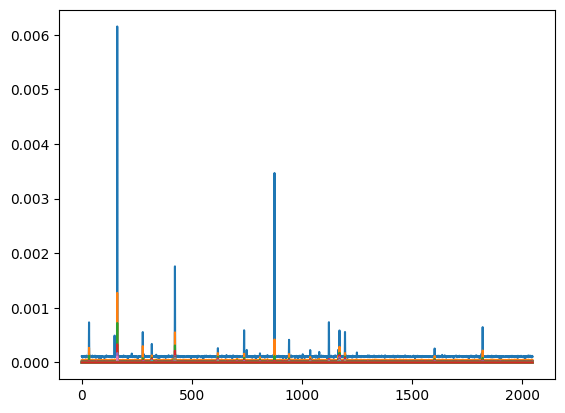

In [9]:
for layer in model.model.layers:
    plt.plot(layer.mlp.grad_imp.cpu())

In [10]:
# collect neuron importance from layers
importance = pd.DataFrame({
    i: layer.mlp.grad_imp.cpu()
    for i, layer in enumerate(model.model.layers)})

importance.to_csv('importance.csv')


---
# Compute MLP output norm


In [11]:
model = get_opt(model_name)
model.eval()
model.to(DEV)

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(49152, 2048)
    (layers): ModuleList(
      (0-23): 24 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (k_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (v_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (up_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (down_proj): Linear(in_features=8192, out_features=2048, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((2048,), eps=1e-05)
    (rotary_emb)

In [12]:
@torch.no_grad()
def compute_mlp_norm(model):
    def hook_mlp(module, inps, outs):
        outs_abs = outs.abs()
        module.norms_L1.extend(
            outs_abs.sum(dim=2).cpu().flatten().tolist())
        module.norms_L2.extend(
            outs_abs.norm(dim=2).cpu().flatten().tolist())
        module.norms_max.extend(
            outs_abs.max(dim=2).values.cpu().flatten().tolist())

    use_cache = model.config.use_cache
    model.config.use_cache = False

    hooks = []
    for layer in model.model.layers:
        layer.mlp.norms_L1 = []
        layer.mlp.norms_L2 = []
        layer.mlp.norms_max = []
        h = layer.mlp.register_forward_hook(hook_mlp)
        hooks.append(h)

    for batch in dataloader:
        model(batch[0].to(DEV))
        torch.cuda.empty_cache()

    model.config.use_cache = use_cache
    for h in hooks:
        h.remove()

compute_mlp_norm(model)

In [13]:
# collect norms from layers
norms_L1 = pd.DataFrame({
    i: layer.mlp.norms_L1
    for i, layer in enumerate(model.model.layers)})
norms_L2 = pd.DataFrame({
    i: layer.mlp.norms_L2
    for i, layer in enumerate(model.model.layers)})
norms_max = pd.DataFrame({
    i: layer.mlp.norms_max
    for i, layer in enumerate(model.model.layers)})

norm_L2_means = norms_L2.mean()

norms_L1.to_csv('norms_L1.csv')
norms_L2.to_csv('norms_L2.csv')
norms_max.to_csv('norms_max.csv')

[14.517113208770752, 18.388416409492493, 19.324568793177605, 25.971057772636414, 28.535166144371033, 31.641284108161926, 36.316221475601196, 52.295472621917725, 50.88528347015381, 57.39054161310196, 58.834558963775635, 61.97533345222473, 59.953614234924316, 66.3242199420929, 80.69355094432831, 92.67101660370827, 115.67223984003067, 144.47405041754246, 192.8752191066742, 232.75766277313232, 257.75736808776855, 306.33427810668945, 417.5819282531738, 1903.5644989013672]


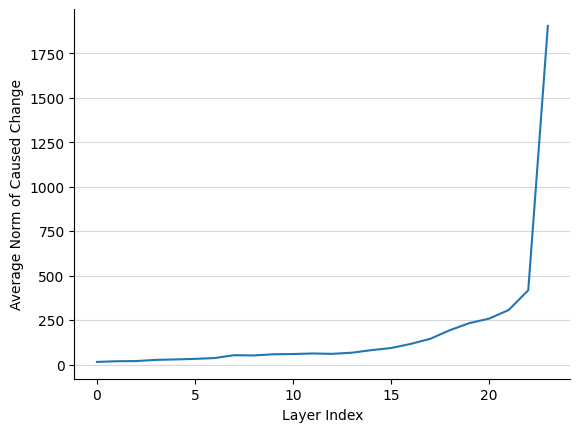

In [14]:
print(list(norm_L2_means))
plt.plot(norm_L2_means)
plt.xlabel('Layer Index')
plt.ylabel('Average Norm of Caused Change')
plt.grid(axis='y', alpha=0.5)
sns.despine()

## Norm distribution

In [ ]:
fig, axes = plt.subplots(4, 6, figsize=(15, 10))
axes = axes.flatten()

for i, column in enumerate(norms_L2.columns):
    ax = axes[i]
    ax.hist(norms_L2[column], bins=15, alpha=0.7, color='blue')
    ax.set_title(f'Layer {column}', fontsize=10)
    if i >= len(norms_L2.columns) - 6:
        ax.set_xlabel('Norm Value', fontsize=8)
    if i % 6 == 0:
        ax.set_ylabel('Frequency', fontsize=8)
    sns.despine()

plt.tight_layout()
plt.show()


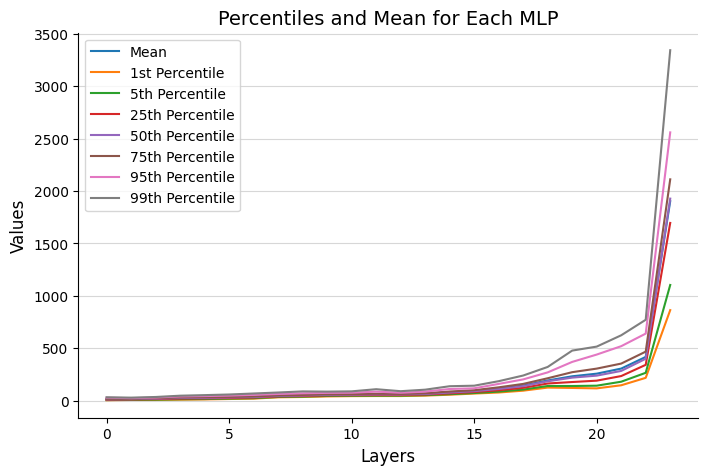

In [16]:
percentiles = [1, 5, 25, 50, 75, 95, 99]

summary = pd.DataFrame({
    "Mean": norms_L2.mean(),
    "1st Percentile": norms_L2.quantile(0.01),
    "5th Percentile": norms_L2.quantile(0.05),
    "25th Percentile": norms_L2.quantile(0.25),
    "50th Percentile": norms_L2.median(),
    "75th Percentile": norms_L2.quantile(0.75),
    "95th Percentile": norms_L2.quantile(0.95),
    "99th Percentile": norms_L2.quantile(0.99)
})

# Plot percentiles and mean for each column
plt.figure(figsize=(8, 5))
for column in summary.columns:
    plt.plot(summary.index, summary[column], label=column)

plt.title("Percentiles and Mean for Each MLP", fontsize=14)
plt.xlabel("Layers", fontsize=12)
plt.ylabel("Values", fontsize=12)
plt.legend(fontsize=10)
plt.grid(axis='y', alpha=0.5)
sns.despine()
plt.show()

# Compute relative norm of MLP output


In [17]:
# using ratio ||f(x)|| / ||x||
# instead of ||f(x)||
@torch.no_grad()
def compute_mlp_rel_norm(model):
    def hook_mlp(module, inps, outs):
        outs_abs = outs.abs()
        inps_abs = inps[0].abs()
        module.rel_norms_L1.extend(
            (outs_abs.sum(dim=2)/inps_abs.sum(dim=2)).cpu().flatten().tolist())
        module.rel_norms_L2.extend(
            (outs_abs.norm(dim=2)/inps_abs.norm(dim=2)).cpu().flatten().tolist())
        module.rel_norms_max.extend(
            (outs_abs.max(dim=2).values/inps_abs.max(dim=2).values).cpu().flatten().tolist())

    use_cache = model.config.use_cache
    model.config.use_cache = False

    hooks = []
    for layer in model.model.layers:
        layer.mlp.rel_norms_L1 = []
        layer.mlp.rel_norms_L2 = []
        layer.mlp.rel_norms_max = []
        h = layer.mlp.register_forward_hook(hook_mlp)
        hooks.append(h)

    for batch in dataloader:
        model(batch[0].to(DEV))
        torch.cuda.empty_cache()

    model.config.use_cache = use_cache
    for h in hooks:
        h.remove()

compute_mlp_rel_norm(model)

In [18]:
# collect norms from layers
rel_norms_L1 = pd.DataFrame({
    i: layer.mlp.rel_norms_L1
    for i, layer in enumerate(model.model.layers)})
rel_norms_L2 = pd.DataFrame({
    i: layer.mlp.rel_norms_L2
    for i, layer in enumerate(model.model.layers)})
rel_norms_max = pd.DataFrame({
    i: layer.mlp.rel_norms_max
    for i, layer in enumerate(model.model.layers)})

rel_norm_L2_means = rel_norms_L2.mean()

rel_norms_L1.to_csv('rel_norms_L1.csv')
rel_norms_L2.to_csv('rel_norms_L2.csv')
rel_norms_max.to_csv('rel_norms_max.csv')

[11.126072764396667, 9.272637605667114, 8.421093374490738, 9.823297441005707, 9.829224675893784, 10.246060013771057, 10.831384301185608, 13.745130777359009, 12.99400544166565, 14.21717655658722, 14.306987881660461, 15.208263993263245, 14.461907386779785, 15.600783467292786, 18.77316701412201, 20.240895584225655, 22.369903177022934, 24.785302683711052, 29.225049018859863, 32.83945679664612, 35.43339204788208, 41.29367971420288, 49.49016809463501, 137.83155155181885]


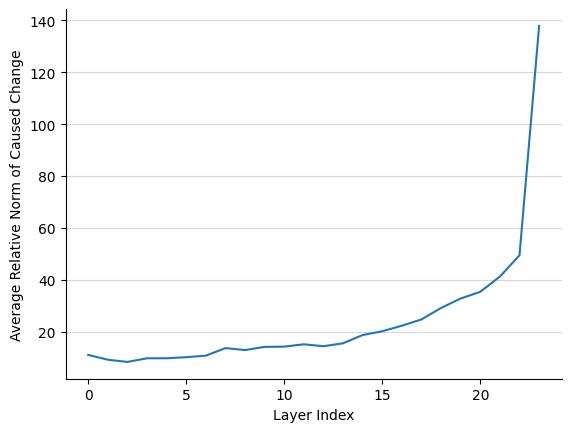

In [19]:
print(list(rel_norm_L2_means))
plt.plot(rel_norm_L2_means)
plt.xlabel('Layer Index')
plt.ylabel('Average Relative Norm of Caused Change')
plt.grid(axis='y', alpha=0.5)
sns.despine()

---
# Compute weighted relative norm of MLP output

In [21]:
for i, layer in enumerate(model.model.layers):
    mlp = layer.mlp
    mlp.grad_imp = torch.Tensor(importance.iloc[:, i])

In [22]:
# weighting individual changes by neuron importance
# using relative norms (ratio ||f(x)|| / ||x|| instead of ||f(x)||)

@torch.no_grad()
def compute_mlp_w_rel_norm(model):
    def hook_mlp(module, inps, outs):
        # take absolute value and weight using grad_imp
        w_outs_abs = outs.abs().cpu() * module.grad_imp
        inps_abs = inps[0].abs().cpu()
        module.w_rel_norms_L1.extend(
            (w_outs_abs.sum(dim=2)/inps_abs.sum(dim=2)).flatten().tolist())
        module.w_rel_norms_L2.extend(
            (w_outs_abs.norm(dim=2)/inps_abs.norm(dim=2)).flatten().tolist())
        module.w_rel_norms_max.extend(
            (w_outs_abs.max(dim=2).values/inps_abs.max(dim=2).values).flatten().tolist())

    use_cache = model.config.use_cache
    model.config.use_cache = False

    hooks = []
    for layer in model.model.layers:
        layer.mlp.w_rel_norms_L1 = []
        layer.mlp.w_rel_norms_L2 = []
        layer.mlp.w_rel_norms_max = []
        h = layer.mlp.register_forward_hook(hook_mlp)
        hooks.append(h)

    for batch in dataloader:
        model(batch[0].to(DEV))
        torch.cuda.empty_cache()

    model.config.use_cache = use_cache
    for h in hooks:
        h.remove()

compute_mlp_w_rel_norm(model)

In [23]:
# collect norms from layers
w_rel_norms_L1 = pd.DataFrame({
    i: layer.mlp.w_rel_norms_L1
    for i, layer in enumerate(model.model.layers)})
w_rel_norms_L2 = pd.DataFrame({
    i: layer.mlp.w_rel_norms_L2
    for i, layer in enumerate(model.model.layers)})
w_rel_norms_max = pd.DataFrame({
    i: layer.mlp.w_rel_norms_max
    for i, layer in enumerate(model.model.layers)})

w_rel_norm_L2_means = w_rel_norms_L2.mean()

w_rel_norms_L1.to_csv('w_rel_norms_L1.csv')
w_rel_norms_L2.to_csv('w_rel_norms_L2.csv')
w_rel_norms_max.to_csv('w_rel_norms_max.csv')

---
# Layer-Skipping Strategies

In [15]:
class SkipMLP(nn.Module):
    def forward(self, x):
        return torch.zeros_like(x, device=DEV)

## Removing layers from the least significant

In [25]:
results = pd.DataFrame(columns=["perplexity", "inference_time", "layer_diff"])

skipped = {}
num_skipped = 0

t0 = time.time()
ppl = eval_ppl(model, wiki_testloader, device=DEV)
t = time.time() - t0
results.loc[num_skipped] = [ppl, t, 0]
print(f'ppl {ppl}, time {t}\n')

for i in norm_L2_means.argsort():
    gc.collect()
    torch.cuda.empty_cache()
    num_skipped += 1
    skipped[i] = copy.deepcopy(model.model.layers[i].mlp)
    model.model.layers[i].mlp = SkipMLP()
    print(f'skipped MLPs {num_skipped} {list(skipped.keys())}')

    t0 = time.time()
    ppl = eval_ppl(model, wiki_testloader, device=DEV)
    t = time.time() - t0
    results.loc[num_skipped] = [ppl, t, norm_L2_means.iloc[i]]
    print(f'ppl {ppl}, time {t}\n')

    if ppl > 1e4: break

# repair
for i, layer in skipped.items():
    model.model.layers[i].mlp = copy.deepcopy(layer)

results.to_csv('results.csv')
results

ppl 7.260688781738281, time 118.73498272895813

skipped MLPs 1 [0]
ppl 205480.921875, time 111.60577440261841



,perplexity,inference_time,layer_diff
0,7.260689,118.734983,0.000000
1,205480.921875,111.605774,14.517113


In [19]:
# keeping the first two layers
results2 = pd.DataFrame(columns=["perplexity", "inference_time", "layer_diff"])

skipped = {}
num_skipped = 0
results2.loc[0] = results.iloc[0]

for i in norm_L2_means.argsort()[2:]:
    gc.collect()
    torch.cuda.empty_cache()
    num_skipped += 1
    skipped[i] = copy.deepcopy(model.model.layers[i].mlp)
    model.model.layers[i].mlp = SkipMLP()
    print(f'skipped MLPs {num_skipped} {list(skipped.keys())}')

    t0 = time.time()
    ppl = eval_ppl(model, wiki_testloader, device=DEV)
    t = time.time() - t0
    results2.loc[num_skipped] = [ppl, t, norm_L2_means.iloc[i]]
    print(f'ppl {ppl}, time {t}\n')

    if ppl > 1e4: break

# repair
for i, layer in skipped.items():
    model.model.layers[i].mlp = copy.deepcopy(layer)

results2.to_csv('results2.csv')
results2

skipped MLPs 1 [2]
ppl 8.404780387878418, time 9.363569498062134

skipped MLPs 2 [2, 3]
ppl 15.28995418548584, time 9.237032175064087

skipped MLPs 3 [2, 3, 4]
ppl 75.13276672363281, time 9.0710289478302

skipped MLPs 4 [2, 3, 4, 5]
ppl 227.93359375, time 8.945168495178223

skipped MLPs 5 [2, 3, 4, 5, 6]
ppl 5963.49951171875, time 8.76164984703064

skipped MLPs 6 [2, 3, 4, 5, 6, 8]
ppl 16087.7119140625, time 8.60029911994934



,perplexity,inference_time,layer_diff
0,7.260689,118.734983,0.000000
1,8.404780,9.363569,19.324569
2,15.289954,9.237032,25.971058
3,75.132767,9.071029,28.535166
4,227.933594,8.945168,31.641284
5,5963.499512,8.761650,36.316221
6,16087.711914,8.600299,50.885283


## Shallow first

In [ ]:
# nespustam lebo pri wikitext to je cca to iste poradie ako ^

In [ ]:
results_shallow = pd.DataFrame(columns=["perplexity", "inference_time", "layer_diff"])

skipped = {}
num_skipped = 0

results_shallow.loc[0] = results.iloc[0]

# when starting from layer 0 => very high perplexity
for i in range(1, 30):
    gc.collect()
    torch.cuda.empty_cache()

    num_skipped += 1
    skipped[i] = copy.deepcopy(model.model.layers[i].mlp)
    model.model.layers[i].mlp = SkipMLP()
    print(f'skipped MLPs {num_skipped} {list(skipped.keys())}')

    t0 = time.time()
    ppl = eval_ppl(model, wiki_testloader, device=DEV)
    t = time.time() - t0
    results_shallow.loc[num_skipped] = [ppl, t, norm_L2_means.iloc[i]]
    print(f'ppl {ppl}, time {t}\n')

    if ppl > 1e4: break

# repair
for i, layer in skipped.items():
    model.model.layers[i].mlp = copy.deepcopy(layer)

results_shallow.to_csv('results_shallow.csv')
results_shallow

## Deep first

In [27]:
results_deep = pd.DataFrame(columns=["perplexity", "inference_time", "layer_diff"])

skipped = {}
num_skipped = 0

results_deep.loc[0] = results.iloc[0]

for i in range(len(model.model.layers)-1, -1, -1):
    gc.collect()
    torch.cuda.empty_cache()

    num_skipped += 1
    skipped[i] = copy.deepcopy(model.model.layers[i].mlp)
    model.model.layers[i].mlp = SkipMLP()
    print(f'skipped MLPs {num_skipped} {list(skipped.keys())}')

    t0 = time.time()
    ppl = eval_ppl(model, wiki_testloader, device=DEV)
    t = time.time() - t0
    results_deep.loc[num_skipped] = [ppl, t, norm_L2_means.iloc[i]]
    print(f'ppl {ppl}, time {t}\n')

    if ppl > 1e4: break

# repair
for i, layer in skipped.items():
    model.model.layers[i].mlp = copy.deepcopy(layer)

results_deep.to_csv('results_deep.csv')
results_deep

skipped MLPs 1 [23]
ppl 19.54170036315918, time 40.198424100875854

skipped MLPs 2 [23, 22]
ppl 46.562435150146484, time 48.91805577278137

skipped MLPs 3 [23, 22, 21]
ppl 79.74234771728516, time 58.21906661987305

skipped MLPs 4 [23, 22, 21, 20]
ppl 199.9649200439453, time 53.288578271865845

skipped MLPs 5 [23, 22, 21, 20, 19]
ppl 415.5325927734375, time 34.325395822525024

skipped MLPs 6 [23, 22, 21, 20, 19, 18]
ppl 2120.968994140625, time 30.37784457206726

skipped MLPs 7 [23, 22, 21, 20, 19, 18, 17]
ppl 13959.5556640625, time 44.571250438690186



,perplexity,inference_time,layer_diff
0,7.260689,118.734983,0.000000
1,19.541700,40.198424,1903.564499
2,46.562435,48.918056,417.581928
3,79.742348,58.219067,306.334278
4,199.964920,53.288578,257.757368
5,415.532593,34.325396,232.757663
6,2120.968994,30.377845,192.875219
7,13959.555664,44.571250,144.474050


In [26]:
# keeping the last layer
results_deep2 = pd.DataFrame(columns=["perplexity", "inference_time", "layer_diff"])

skipped = {}
num_skipped = 0

results_deep2.loc[0] = results.iloc[0]

for i in range(len(model.model.layers)-2, -1, -1):
    gc.collect()
    torch.cuda.empty_cache()

    num_skipped += 1
    skipped[i] = copy.deepcopy(model.model.layers[i].mlp)
    model.model.layers[i].mlp = SkipMLP()
    print(f'skipped MLPs {num_skipped} {list(skipped.keys())}')

    t0 = time.time()
    ppl = eval_ppl(model, wiki_testloader, device=DEV)
    t = time.time() - t0
    results_deep2.loc[num_skipped] = [ppl, t, norm_L2_means.iloc[i]]
    print(f'ppl {ppl}, time {t}\n')

    if ppl > 1e4: break

# repair
for i, layer in skipped.items():
    model.model.layers[i].mlp = copy.deepcopy(layer)

results_deep2.to_csv('results_deep2.csv')
results_deep2

skipped MLPs 1 [22]
ppl 9.219160079956055, time 111.68365907669067

skipped MLPs 2 [22, 21]
ppl 11.802694320678711, time 106.78074336051941

skipped MLPs 3 [22, 21, 20]
ppl 18.034997940063477, time 102.74846959114075

skipped MLPs 4 [22, 21, 20, 19]
ppl 26.99382972717285, time 55.90725564956665

skipped MLPs 5 [22, 21, 20, 19, 18]
ppl 55.10776901245117, time 51.374364614486694

skipped MLPs 6 [22, 21, 20, 19, 18, 17]
ppl 103.0418472290039, time 47.62266397476196

skipped MLPs 7 [22, 21, 20, 19, 18, 17, 16]
ppl 206.48678588867188, time 44.55328726768494

skipped MLPs 8 [22, 21, 20, 19, 18, 17, 16, 15]
ppl 462.5823669433594, time 43.64814257621765

skipped MLPs 9 [22, 21, 20, 19, 18, 17, 16, 15, 14]
ppl 1071.9088134765625, time 57.1745548248291

skipped MLPs 10 [22, 21, 20, 19, 18, 17, 16, 15, 14, 13]
ppl 2504.923828125, time 38.10883116722107

skipped MLPs 11 [22, 21, 20, 19, 18, 17, 16, 15, 14, 13, 12]
ppl 4524.35205078125, time 36.764837980270386

skipped MLPs 12 [22, 21, 20, 19, 18, 

,perplexity,inference_time,layer_diff
0,7.260689,118.734983,0.000000
1,9.219160,111.683659,417.581928
2,11.802694,106.780743,306.334278
3,18.034998,102.748470,257.757368
4,26.993830,55.907256,232.757663
5,55.107769,51.374365,192.875219
6,103.041847,47.622664,144.474050
7,206.486786,44.553287,115.672240
8,462.582367,43.648143,92.671017
9,1071.908813,57.174555,80.693551


## Removing layers in random order

In [18]:
results_rand = pd.DataFrame(columns=["perplexity", "inference_time", "layer_diff"])

indices = list(range(1, len(model.model.layers)))
random.shuffle(indices)
print(indices)
skipped = {}
num_skipped = 0

results_rand.loc[0] = results.iloc[0]

for i in indices:
    gc.collect()
    torch.cuda.empty_cache()

    num_skipped += 1
    skipped[i] = copy.deepcopy(model.model.layers[i].mlp)
    model.model.layers[i].mlp = SkipMLP()
    print(f'skipped MLPs {num_skipped} {list(skipped.keys())}')

    t0 = time.time()
    ppl = eval_ppl(model, wiki_testloader, device=DEV)
    t = time.time() - t0
    results_rand.loc[num_skipped] = [ppl, t, norm_L2_means.iloc[i]]
    print(f'ppl {ppl}, time {t}\n')

    if ppl > 1e4: break

# repair
for i, layer in skipped.items():
    model.model.layers[i].mlp = copy.deepcopy(layer)

results_rand.to_csv('results_rand.csv')
results_rand

[17, 13, 6, 20, 9, 5, 7, 3, 19, 15, 10, 4, 2, 14, 12, 18, 8, 11, 16, 1, 21, 22, 23]
skipped MLPs 1 [17]
ppl 8.556988716125488, time 9.251898288726807

skipped MLPs 2 [17, 13]
ppl 9.421856880187988, time 9.03812861442566

skipped MLPs 3 [17, 13, 6]
ppl 25.965190887451172, time 8.906183242797852

skipped MLPs 4 [17, 13, 6, 20]
ppl 34.7193603515625, time 8.765807390213013

skipped MLPs 5 [17, 13, 6, 20, 9]
ppl 51.2685661315918, time 8.64929723739624

skipped MLPs 6 [17, 13, 6, 20, 9, 5]
ppl 75.61019134521484, time 8.482697010040283

skipped MLPs 7 [17, 13, 6, 20, 9, 5, 7]
ppl 5157.16552734375, time 8.311204671859741

skipped MLPs 8 [17, 13, 6, 20, 9, 5, 7, 3]
ppl 23367.982421875, time 8.160892486572266



,perplexity,inference_time,layer_diff
0,7.260689,118.734983,0.000000
1,8.556989,9.251898,144.474050
2,9.421857,9.038129,66.324220
3,25.965191,8.906183,36.316221
4,34.719360,8.765807,257.757368
5,51.268566,8.649297,57.390542
6,75.610191,8.482697,31.641284
7,5157.165527,8.311205,52.295473
8,23367.982422,8.160892,25.971058


# Overall Layer Importance

## Removing a single layer

In [29]:
results_1_layer = pd.DataFrame(columns=["perplexity", "inference_time", "layer_diff"])

skipped = {}

for i in range(len(model.model.layers)):
    gc.collect()
    torch.cuda.empty_cache()

    skipped[i] = copy.deepcopy(model.model.layers[i].mlp)
    model.model.layers[i].mlp = SkipMLP()
    print(f'skipped MLP {i}')

    t0 = time.time()
    ppl = eval_ppl(model, wiki_testloader, device=DEV)
    t = time.time() - t0
    results_1_layer.loc[i] = [ppl, t, norm_L2_means.iloc[i]]
    print(f'ppl {ppl}, time {t}\n')

    # repair
    model.model.layers[i].mlp = copy.deepcopy(skipped[i])

results_1_layer.to_csv('results_1_layer.csv')
results_1_layer

skipped MLP 0
ppl 205480.921875, time 48.67481780052185

skipped MLP 1
ppl 65260.95703125, time 62.98082971572876

skipped MLP 2
ppl 8.404780387878418, time 71.05840015411377

skipped MLP 3
ppl 8.325299263000488, time 63.70631146430969

skipped MLP 4
ppl 8.05213737487793, time 72.47028493881226

skipped MLP 5
ppl 7.853992462158203, time 72.55497312545776

skipped MLP 6
ppl 19.5169620513916, time 73.54359483718872

skipped MLP 7
ppl 134.67596435546875, time 72.81938052177429

skipped MLP 8
ppl 8.031761169433594, time 68.49798011779785

skipped MLP 9
ppl 7.935673713684082, time 42.20008111000061

skipped MLP 10
ppl 7.825850486755371, time 61.20487570762634

skipped MLP 11
ppl 7.758394241333008, time 65.358225107193

skipped MLP 12
ppl 7.6639604568481445, time 46.25636315345764

skipped MLP 13
ppl 7.714289665222168, time 46.81652617454529

skipped MLP 14
ppl 7.738760948181152, time 62.79932999610901

skipped MLP 15
ppl 7.883899688720703, time 68.06597304344177

skipped MLP 16
ppl 8.201420

,perplexity,inference_time,layer_diff
0,205480.921875,48.674818,14.517113
1,65260.957031,62.980830,18.388416
2,8.404780,71.058400,19.324569
3,8.325299,63.706311,25.971058
4,8.052137,72.470285,28.535166
5,7.853992,72.554973,31.641284
6,19.516962,73.543595,36.316221
7,134.675964,72.819381,52.295473
8,8.031761,68.497980,50.885283
9,7.935674,42.200081,57.390542


## Removing layers based on overall importance

In [30]:
results_overall_imp = pd.DataFrame(columns=["perplexity", "inference_time", "layer_diff"])

indices = results_1_layer.perplexity.argsort()
print(indices.to_list())
skipped = {}
num_skipped = 0

results_overall_imp.loc[0] = results.iloc[0]

for i in indices:
    gc.collect()
    torch.cuda.empty_cache()

    num_skipped += 1
    skipped[i] = copy.deepcopy(model.model.layers[i].mlp)
    model.model.layers[i].mlp = SkipMLP()
    print(f'skipped MLPs {num_skipped} {list(skipped.keys())}')

    t0 = time.time()
    ppl = eval_ppl(model, wiki_testloader, device=DEV)
    t = time.time() - t0
    results_overall_imp.loc[num_skipped] = [ppl, t, norm_L2_means.iloc[i]]
    print(f'ppl {ppl}, time {t}\n')

    if ppl > 1e4: break

# repair
for i, layer in skipped.items():
    model.model.layers[i].mlp = copy.deepcopy(layer)

results_overall_imp.to_csv('results_overall_imp.csv')
results_overall_imp

[12, 13, 14, 11, 10, 5, 15, 9, 8, 4, 16, 3, 2, 17, 18, 20, 21, 19, 22, 6, 23, 7, 1, 0]
skipped MLPs 1 [12]
ppl 7.6639604568481445, time 29.727046012878418

skipped MLPs 2 [12, 13]
ppl 8.323542594909668, time 27.980647563934326

skipped MLPs 3 [12, 13, 14]
ppl 9.485733985900879, time 27.053013801574707

skipped MLPs 4 [12, 13, 14, 11]
ppl 11.678743362426758, time 26.014779806137085

skipped MLPs 5 [12, 13, 14, 11, 10]
ppl 59.53540802001953, time 24.784696578979492

skipped MLPs 6 [12, 13, 14, 11, 10, 5]
ppl 50.23979568481445, time 23.679094791412354

skipped MLPs 7 [12, 13, 14, 11, 10, 5, 15]
ppl 102.911376953125, time 23.659913063049316

skipped MLPs 8 [12, 13, 14, 11, 10, 5, 15, 9]
ppl 396.33648681640625, time 22.049362659454346

skipped MLPs 9 [12, 13, 14, 11, 10, 5, 15, 9, 8]
ppl 47947.984375, time 21.066295385360718



,perplexity,inference_time,layer_diff
0,7.260689,118.734983,0.000000
1,7.663960,29.727046,59.953614
2,8.323543,27.980648,66.324220
3,9.485734,27.053014,80.693551
4,11.678743,26.014780,61.975333
5,59.535408,24.784697,58.834559
6,50.239796,23.679095,31.641284
7,102.911377,23.659913,92.671017
8,396.336487,22.049363,57.390542
9,47947.984375,21.066295,50.885283


# Results

In [20]:
results_rand.loc[:, 'log_perplexity'] = [np.log(x) for x in results_rand.perplexity]
results.loc[:, 'log_perplexity'] = [np.log(x) for x in results.perplexity]
results2.loc[:, 'log_perplexity'] = [np.log(x) for x in results2.perplexity]
results_deep.loc[:, 'log_perplexity'] = [np.log(x) for x in results_deep.perplexity]
results_deep2.loc[:, 'log_perplexity'] = [np.log(x) for x in results_deep2.perplexity]
results_rand.loc[:, 'log_perplexity'] = [np.log(x) for x in results_rand.perplexity]
results_1_layer.loc[:, 'log_perplexity'] = [np.log(x) for x in results_1_layer.perplexity]
results_overall_imp.loc[:, 'log_perplexity'] = [np.log(x) for x in results_overall_imp.perplexity]
# results_threshold_L1.loc[:, 'log_perplexity'] = [np.log(x) for x in results_threshold_L1.perplexity]
# results_threshold_L2.loc[:, 'log_perplexity'] = [np.log(x) for x in results_threshold_L2.perplexity]
# results_threshold_max.loc[:, 'log_perplexity'] = [np.log(x) for x in results_threshold_max.perplexity]

### Layer Importance

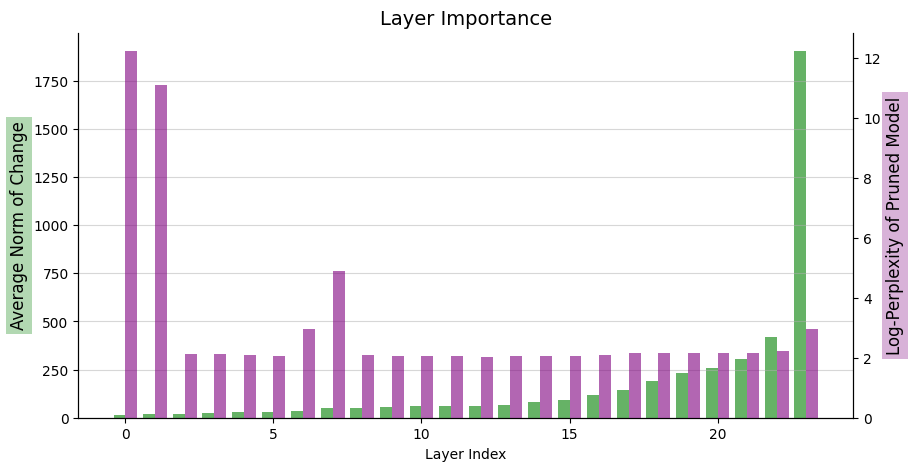

In [22]:
fig, ax1 = plt.subplots(figsize=(10, 5))

layer_indices = np.arange(len(norms_L2.mean()))  # X-axis positions
width = 0.4  # Width of bars

# Primary y-axis for norms (Bar plot)
ax1.bar(layer_indices - width/2, norms_L2.mean(), width=width, label='Norm', color='green', alpha=0.6)
ax1.set_xlabel('Layer Index')
ax1.set_ylabel('Average Norm of Change', fontsize=12,
               bbox=dict(facecolor='green', alpha=0.3, edgecolor='none', pad=3))
ax1.set_xticks(range(0, len(norms_L2.mean()), 5))
ax1.grid(axis='y', alpha=0.5)

# Secondary y-axis for perplexity (Bar plot)
ax2 = ax1.twinx()
ax2.bar(layer_indices + width/2, results_1_layer.log_perplexity, width=width,
        label='Log-Perplexity', color='purple', alpha=0.6)
ax2.set_ylabel('Log-Perplexity of Pruned Model', fontsize=12,
               bbox=dict(facecolor='purple', alpha=0.3, edgecolor='none', pad=3))
plt.title("Layer Importance", fontsize=14)

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
# ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper center')

sns.despine(right=False)  # Keep right spine for secondary axis
plt.show()


## Multiple layers - different strategies

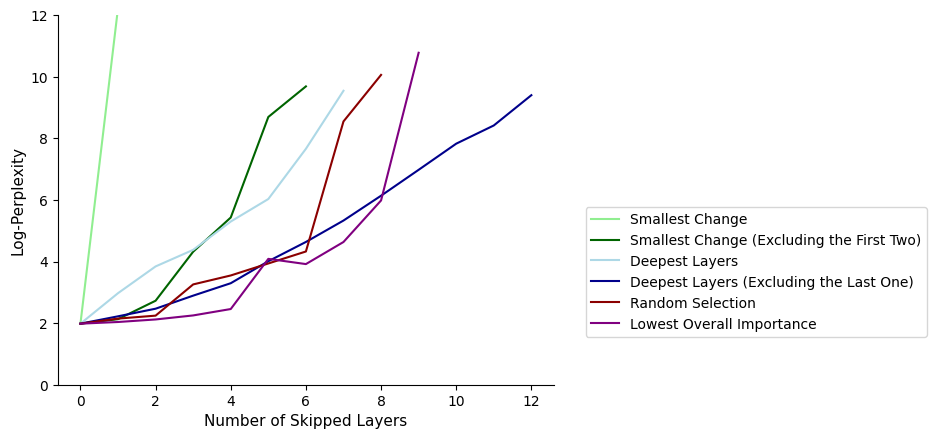

In [22]:
plt.plot(results.log_perplexity, label='Smallest Change', color='lightgreen')
plt.plot(results2.log_perplexity, label='Smallest Change (Excluding the First Two)', color='darkgreen')
plt.plot(results_deep.log_perplexity, label='Deepest Layers', color='lightblue')
plt.plot(results_deep2.log_perplexity, label='Deepest Layers (Excluding the Last One)', color='darkblue')
# plt.plot(results_shallow.log_perplexity, label='Shallow Layers')
plt.plot(results_rand.log_perplexity, label='Random Selection', color='darkred')
plt.plot(results_overall_imp.log_perplexity, label='Lowest Overall Importance', color='purple')

plt.xlabel('Number of Skipped Layers', fontsize=11)
plt.ylabel('Log-Perplexity', fontsize=11)
plt.ylim((0, 12))
# plt.legend(loc='lower right')
plt.legend(bbox_to_anchor=(1.05, 0.5))
# plt.title('Layer-Skipping Strategies')
sns.despine()

# Deleting small changes

In [28]:
gc.collect()
torch.cuda.empty_cache()

In [29]:
@torch.no_grad()
def delete_small_changes(model):
    def hook_l1_threshold(module, inps, outs):
        token_norms = outs.abs().sum(dim=2, keepdim=True)
        mask = token_norms >= module.threshold_L1
        ratio_over_thr.append(mask.sum().item() / mask.numel())
        return outs * mask

    def hook_l2_threshold(module, inps, outs):
        token_norms = outs.norm(dim=2, keepdim=True)
        mask = token_norms >= module.threshold_L2
        ratio_over_thr.append(mask.sum().item() / mask.numel())
        return outs * mask

    def hook_max_threshold(module, inps, outs):
        token_norms = outs.abs().max(dim=2, keepdim=True).values
        mask = token_norms >= module.threshold_max
        ratio_over_thr.append(mask.sum().item() / mask.numel())
        return outs * mask

    norm_types = ('L1', 'L2', 'max')

    use_cache = model.config.use_cache
    model.config.use_cache = False
    gc.collect()
    torch.cuda.empty_cache()

    index = pd.MultiIndex(levels=[[], []], codes=[[], []], names=['norm_type', 'threshold'])
    results_threshold = pd.DataFrame(columns=['perplexity', 'ratio_del'], index=index)

    # for q in (0.2, 0.15, 0.1, 0.05, 0.01, 0.001, 1e-4):
    for q in range(10, 71, 10):
        print(f'percentile {q}')
        q /= 100
        # set thresholds for each layer
        for i, layer in enumerate(model.model.layers):
            mlp = layer.mlp
            mlp.threshold_L1 = mlp.thresholds_L1[q]
            mlp.threshold_L2 = mlp.thresholds_L2[q]
            mlp.threshold_max = mlp.thresholds_max[q]

        for norm_type, hook in zip(norm_types, (hook_l1_threshold, hook_l2_threshold, hook_max_threshold)):
            # register hooks
            hooks = []
            ratio_over_thr = []
            for i, layer in enumerate(model.model.layers):
                mlp = layer.mlp
                h = mlp.register_forward_hook(hook)
                hooks.append(h)
            # evaluate
            ppl = eval_ppl(model, wiki_testloader, device=DEV)
            ratio_del = 1 - np.mean(ratio_over_thr)
            # save results
            print(f'{norm_type} norm\t--> deleted ratio {ratio_del*100:.6f}, ppl {ppl:.6f}')
            results_threshold.loc[(norm_type, q*100), :] = [ppl, ratio_del]

            for h in hooks:
                h.remove()

        print()

    model.config.use_cache = use_cache

    return results_threshold

results_threshold = delete_small_changes(model)
results_threshold = results_threshold.unstack(level=0)
results_threshold.to_csv('results_threshold.csv')

percentile 10
L1 norm	--> deleted ratio 14.827144, ppl 19.774139
L2 norm	--> deleted ratio 7.936289, ppl 12.265088
max norm	--> deleted ratio 9.436214, ppl 14.614442

percentile 20
L1 norm	--> deleted ratio 43.221194, ppl 1270.238281
L2 norm	--> deleted ratio 22.553315, ppl 84.064819
max norm	--> deleted ratio 15.109775, ppl 49.273273

percentile 30
L1 norm	--> deleted ratio 51.323707, ppl 62036.171875
L2 norm	--> deleted ratio 39.930574, ppl 929.326172
max norm	--> deleted ratio 20.753355, ppl 389.697815

percentile 40
L1 norm	--> deleted ratio 57.021930, ppl 759595.000000
L2 norm	--> deleted ratio 45.890891, ppl 20587.371094
max norm	--> deleted ratio 29.218945, ppl 2045.323120

percentile 50
L1 norm	--> deleted ratio 61.343109, ppl 4319788.500000
L2 norm	--> deleted ratio 48.069873, ppl 88003.835938
max norm	--> deleted ratio 41.846390, ppl 7497.294922

percentile 60
L1 norm	--> deleted ratio 65.676522, ppl 3551108.500000
L2 norm	--> deleted ratio 49.349110, ppl 264288.750000
max no

## Results

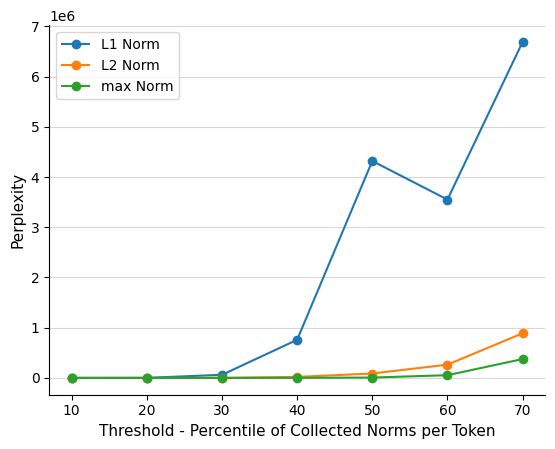

In [28]:
# podla akeho percetilu bol nastaveny threshold
plt.plot(results_threshold.index, results_threshold.loc[:, ('perplexity', 'L1')], label='L1 Norm', marker='o')
plt.plot(results_threshold.index, results_threshold.loc[:, ('perplexity', 'L2')], label='L2 Norm', marker='o')
plt.plot(results_threshold.index, results_threshold.loc[:, ('perplexity', 'max')], label='max Norm', marker='o')
plt.xlabel('Threshold - Percentile of Collected Norms per Token', fontsize=11)
plt.ylabel('Perplexity', fontsize=11)
plt.legend()
plt.grid(axis='y', alpha=0.5)
sns.despine()

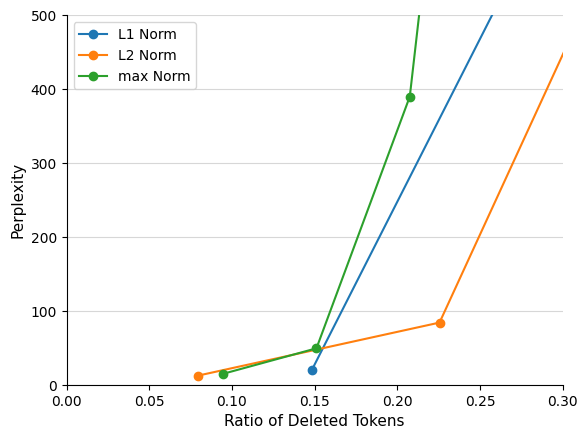

In [27]:
# kolko hodnot bolo realne vynulovanych
plt.plot(results_threshold.loc[:, ('ratio_del', 'L1')], results_threshold.loc[:, ('perplexity', 'L1')], label='L1 Norm', marker='o')
plt.plot(results_threshold.loc[:, ('ratio_del', 'L2')], results_threshold.loc[:, ('perplexity', 'L2')], label='L2 Norm', marker='o')
plt.plot(results_threshold.loc[:, ('ratio_del', 'max')], results_threshold.loc[:, ('perplexity', 'max')], label='max Norm', marker='o')
plt.xlim((0, 0.3))
plt.ylim((0, 500))
plt.xlabel('Ratio of Deleted Tokens', fontsize=11)
plt.ylabel('Perplexity', fontsize=11)
plt.legend()
plt.grid(axis='y', alpha=0.5)
sns.despine()

## Keeping some layers unchanged

### Which layers are important to keep

In [ ]:
# using l2 norm, quantile 0.3
@torch.no_grad()
def undo_small_changes(model):
    def l2_threshold(module, inps, outs):
        token_norms = outs.norm(dim=2, keepdim=True)
        mask = token_norms >= module.threshold_L2
        ratio_over_thr.append(mask.sum().item() / mask.numel())
        return outs * mask
        
    q = 0.3
    last = len(model.model.layers) - 1
    imp_order = results_1_layer.perplexity.argsort()[::-1]
    layer_combinations = [
        (), (0,), (last,),
         (0, 1), (0, 1, 2), (0, 1, 2, 3),
        (0, last), (0, last-1, last), (0, last-2, last-1, last),
        (0, 1, last), (0, 1, last-1, last), (0, 1, 2, last)
    ] + [
        tuple(results_1_layer.perplexity.argsort()[::-1])[:i] for i in range(2, 5)
    ]

    use_cache = model.config.use_cache
    model.config.use_cache = False

    gc.collect()
    torch.cuda.empty_cache()

    results_thr_keeping_layers = pd.DataFrame(columns=['perplexity', 'ratio_del'])

    for ls in layer_combinations:
        print('layers kept unchanged:', ls)
        hooks = []
        ratio_over_thr = []
        for i, layer in enumerate(model.model.layers):
            if i in ls:
                ratio_over_thr.append(1)
                continue

            mlp = layer.mlp
            mlp.threshold_L2 = mlp.norms_L2.quantile(q)
            h = mlp.register_forward_hook(l2_threshold)
            hooks.append(h)

        ppl = eval_ppl(model, wiki_testloader, device=DEV)
        ratio_del = 1 - np.mean(ratio_over_thr)
        print(f'deleted ratio {ratio_del*100:.2f} --> ppl {ppl:.2f}')
        results_thr_keeping_layers.loc[str(ls)] = [ppl, ratio_del]

        for h in hooks:
            h.remove()

    model.config.use_cache = use_cache

    return results_thr_keeping_layers

results_thr_keeping_layers = undo_small_changes(model)
results_thr_keeping_layers.to_csv('results_thr_keeping_layers.csv')

In [35]:
results_thr_keeping_layers

,perplexity,ratio_del
(),929.326172,0.399306
"(0,)",128.345993,0.351830
"(23,)",196.864746,0.377086
"(0, 1)",100.676147,0.350486
"(0, 1, 2)",66.108734,0.328414
"(0, 1, 2, 3)",46.582100,0.318289
"(0, 23)",41.073849,0.332854
"(0, 22, 23)",32.205215,0.313359
"(0, 21, 22, 23)",26.508076,0.295481
"(0, 1, 23)",33.143436,0.332217


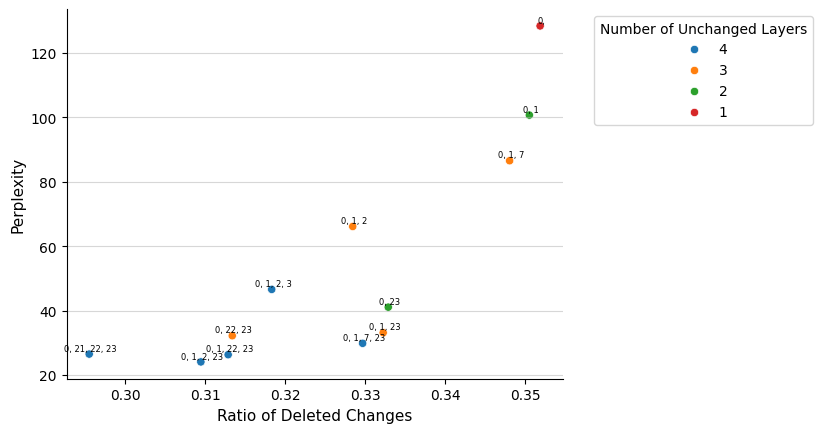

In [36]:
rtkl = results_thr_keeping_layers.sort_values(by='perplexity')[:-2]
rtkl['num_layers_untouched'] = list(map(lambda x: len(x[1:-1].split(', ')), rtkl.index))

categories = rtkl.num_layers_untouched.astype(str)
palette = sns.color_palette("tab10", n_colors=len(categories.unique()))
sns.scatterplot(x=rtkl.ratio_del, y=rtkl.perplexity, hue=categories, palette=palette)

for i, txt in enumerate(rtkl.index):
    plt.text(rtkl.ratio_del.iloc[i]+0.0002, rtkl.perplexity.iloc[i]+0.4, txt[1:-1], fontsize=6, ha='center', va='bottom')

plt.xlabel('Ratio of Deleted Changes', fontsize=11)
plt.ylabel('Perplexity', fontsize=11)
plt.grid(axis='y', alpha=0.5)
plt.legend(title="Number of Unchanged Layers", bbox_to_anchor=(1.05, 1), loc='upper left')
sns.despine()
plt.show()

In [38]:
# layer combinations with best ratios
(results_thr_keeping_layers.perplexity/results_thr_keeping_layers.ratio_del).sort_values().iloc[:5]

(0, 1, 2, 23)      77.802089
(0, 1, 22, 23)     84.126124
(0, 21, 22, 23)    89.711697
(0, 1, 7, 23)      90.543665
(0, 1, 23)         99.764275
dtype: float64

### Different thresholds and norm types

In [ ]:
layers_to_keep = (0, 1, 23)

@torch.no_grad()
def undo_small_changes(model):
    def hook_l1_threshold(module, inps, outs):
        token_norms = outs.abs().sum(dim=2, keepdim=True)
        mask = token_norms >= module.threshold_L1
        ratio_over_thr.append(mask.sum().item() / mask.numel())
        return outs * mask

    def hook_l2_threshold(module, inps, outs):
        token_norms = outs.norm(dim=2, keepdim=True)
        mask = token_norms >= module.threshold_L2
        ratio_over_thr.append(mask.sum().item() / mask.numel())
        return outs * mask

    def hook_max_threshold(module, inps, outs):
        token_norms = outs.abs().max(dim=2, keepdim=True).values
        mask = token_norms >= module.threshold_max
        ratio_over_thr.append(mask.sum().item() / mask.numel())
        return outs * mask

    norm_types = ('L1', 'L2', 'max')

    use_cache = model.config.use_cache
    model.config.use_cache = False
    gc.collect()
    torch.cuda.empty_cache()

    index = pd.MultiIndex(levels=[[], []], codes=[[], []], names=['norm_type', 'threshold'])
    results_threshold = pd.DataFrame(columns=['perplexity', 'ratio_del'], index=index)

    for q in range(10, 71, 10):
        print(f'percentile {q}')
        q /= 100
        # set thresholds for each layer
        for i, layer in enumerate(model.model.layers):
            mlp = layer.mlp
            mlp.threshold_L1 = mlp.norms_L1.quantile(q)
            mlp.threshold_L2 = mlp.norms_L2.quantile(q)
            mlp.threshold_max = mlp.norms_max.quantile(q)

        for norm_type, hook in zip(norm_types, (hook_l1_threshold, hook_l2_threshold, hook_max_threshold)):
            # register hooks
            hooks = []
            ratio_over_thr = []
            for i, layer in enumerate(model.model.layers):
                if i in layers_to_keep:
                    ratio_over_thr.append(1)
                    continue
                mlp = layer.mlp
                h = mlp.register_forward_hook(hook)
                hooks.append(h)
            # evaluate
            ppl = eval_ppl(model, wiki_testloader, device=DEV)
            ratio_del = 1 - np.mean(ratio_over_thr)
            # save results
            print(f'{norm_type} norm\t--> deleted ratio {ratio_del*100:.6f}, ppl {ppl:.6f}')
            results_threshold.loc[(norm_type, q*100), :] = [ppl, ratio_del]

            for h in hooks:
                h.remove()

        print()

    model.config.use_cache = use_cache

    return results_threshold

results_threshold_except = undo_small_changes(model)
results_threshold_except = results_threshold_except.unstack(level=0)
results_threshold_except.to_csv('results_threshold_except.csv')

### Results

## Using relative norm

In [43]:
def rel_L1_norm(inps_abs, outs_abs):
    return outs_abs.sum(dim=2, keepdim=True) / inps_abs.sum(dim=2, keepdim=True)


def rel_L2_norm(inps_abs, outs_abs):
    return outs_abs.norm(dim=2, keepdim=True) / inps_abs.norm(dim=2, keepdim=True)


def rel_max_norm(inps_abs, outs_abs):
    return outs_abs.max(dim=2, keepdim=True).values / inps_abs.max(dim=2, keepdim=True).values

In [44]:
def get_rel_L1_threshold(module):
    return module.threshold_rel_L1


def get_rel_L2_threshold(module):
    return module.threshold_rel_L2


def get_rel_max_threshold(module):
    return module.threshold_rel_max


def get_w_rel_L1_threshold(module):
    return module.threshold_w_rel_L1


def get_w_rel_L2_threshold(module):
    return module.threshold_w_rel_L2


def get_w_rel_max_threshold(module):
    return module.threshold_w_rel_max

In [ ]:
@torch.no_grad()
def undo_small_rel_changes(model):
    def hook_threshold(module, inps, outs):
        token_norms = norm_function(inps[0].abs(), outs.abs())
        mask = token_norms >= get_threshold(module)
        ratio_over_thr.append(mask.sum().item() / mask.numel())
        return outs * mask

    use_cache = model.config.use_cache
    model.config.use_cache = False
    gc.collect()
    torch.cuda.empty_cache()

    index = pd.MultiIndex(levels=[[], []], codes=[[], []], names=['norm_type', 'threshold'])
    results_threshold_rel = pd.DataFrame(columns=['perplexity', 'ratio_del'], index=index)

    norm_types = ('L1', 'L2', 'max')
    for q in range(10, 71, 10):
        print(f'percentile {q}')
        q /= 100
        # set thresholds for each layer
        for i, layer in enumerate(model.model.layers):
            mlp = layer.mlp
            mlp.threshold_rel_L1 = mlp.rel_norms_L1.quantile(q)
            mlp.threshold_rel_L2 = mlp.rel_norms_L2.quantile(q)
            mlp.threshold_rel_max = mlp.rel_norms_max.quantile(q)

        for norm_type, norm_function, get_threshold in zip(
                norm_types,
                (rel_L1_norm, rel_L2_norm, rel_max_norm),
                (get_rel_L1_threshold, get_rel_L2_threshold, get_rel_max_threshold)):
            # register hooks
            hooks = []
            ratio_over_thr = []
            for i, layer in enumerate(model.model.layers):
                if i in layers_to_keep:
                    ratio_over_thr.append(1)
                    continue
                mlp = layer.mlp
                h = mlp.register_forward_hook(hook_threshold)
                hooks.append(h)
            # evaluate
            ppl = eval_ppl(model, wiki_testloader, device=DEV)
            ratio_del = 1 - np.mean(ratio_over_thr)
            # save results
            print(f'{norm_type} norm\t\t--> deleted ratio {ratio_del*100:.6f}, ppl {ppl:.6f}')
            results_threshold_rel.loc[(norm_type, q*100), :] = [ppl, ratio_del]

            for h in hooks:
                h.remove()

        print()

    model.config.use_cache = use_cache
    return results_threshold_rel

results_threshold_rel_except = undo_small_rel_changes(model)
results_threshold_rel_except = results_threshold_rel_except.unstack(level=0)
results_threshold_rel_except.to_csv('results_threshold_rel_except.csv')

### Results

#### Results using absolute norm

In [48]:
results_threshold_except

perplexity                            ratio_del            \
norm_type           L1           L2           max        L1        L2   
threshold                                                               
10.0         14.194742     8.982807      9.072396  0.105584  0.074518   
20.0         39.843781    15.122994     12.848275   0.26313  0.209278   
30.0         96.594688    33.143436      21.68099  0.383597  0.332217   
40.0        265.134277    87.764954     52.097916  0.480328  0.434363   
50.0        706.248108   228.704926    192.507507  0.558485  0.510476   
60.0       1812.629639   568.925781   8164.916016  0.619582  0.570046   
70.0       3922.534424  1310.560059  41993.511719  0.669331  0.621495   

                     
norm_type       max  
threshold            
10.0       0.099451  
20.0       0.175619  
30.0       0.248578  
40.0       0.331562  
50.0       0.425958  
60.0        0.55575  
70.0       0.725867

#### Results using relative norm

In [49]:
results_threshold_rel_except

perplexity                          ratio_del                    
norm_type           L1          L2          max        L1        L2       max
threshold                                                                    
10.0          7.972623    7.920609     8.971434  0.084726  0.082116  0.095245
20.0         12.126037   10.678616    12.474029  0.217589  0.190546    0.1667
30.0         32.519547   19.263123    19.916609  0.369392  0.300016   0.23335
40.0        109.271408   45.956844    45.918053  0.493702  0.403762  0.298371
50.0         312.60257  121.489937   107.759163  0.581535  0.483643  0.364036
60.0        756.254822  317.927917   608.181519  0.651901  0.544569  0.448044
70.0       1752.414673  760.097107  3535.494873  0.707494  0.596988  0.560039

#### Norm type comparison

##### Absolute norm

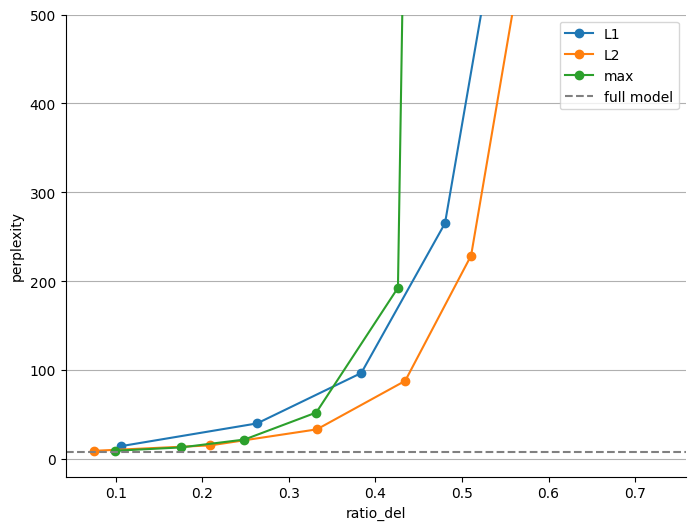

In [50]:
plt.figure(figsize=(8, 6))
norm_types = ["L1", "L2", "max"]
for norm in norm_types:
    plt.plot(results_threshold_except["ratio_del", norm], results_threshold_except["perplexity", norm], marker='o', label=norm)
plt.axhline(results.loc[0, 'perplexity'], c='gray', linestyle='--', label='full model')
plt.ylim(-20, 500)
plt.xlabel("ratio_del")
plt.ylabel("perplexity")
plt.legend()
plt.grid(axis='y')
sns.despine()
plt.show()

##### Relative norm

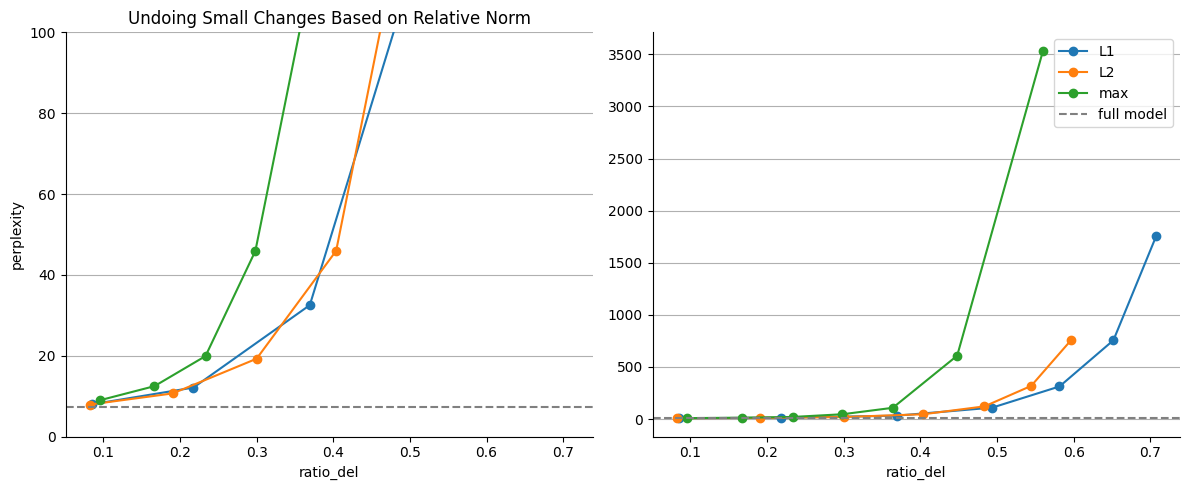

In [51]:
norm_types = ["L1", "L2", "max"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for norm in norm_types:
    axes[0].plot(results_threshold_rel_except["ratio_del", norm],
                 results_threshold_rel_except["perplexity", norm],
                 marker='o', label=norm)
axes[0].axhline(results.loc[0, 'perplexity'], c='gray', linestyle='--', label='full model')
axes[0].set_title("Undoing Small Changes Based on Relative Norm")
axes[0].set_xlabel("ratio_del")
axes[0].set_ylabel("perplexity")
axes[0].set_ylim(0, 100)
# axes[0].legend()
axes[0].grid(axis='y')

for norm in norm_types:
    axes[1].plot(results_threshold_rel_except["ratio_del", norm],
                 results_threshold_rel_except["perplexity", norm],
                 marker='o', label=norm)
axes[1].axhline(results.loc[0, 'perplexity'], c='gray', linestyle='--', label='full model')
axes[1].set_xlabel("ratio_del")
axes[1].legend()
axes[1].grid(axis='y')

sns.despine()
plt.tight_layout()
plt.show()


#### Relative vs. absolute norm

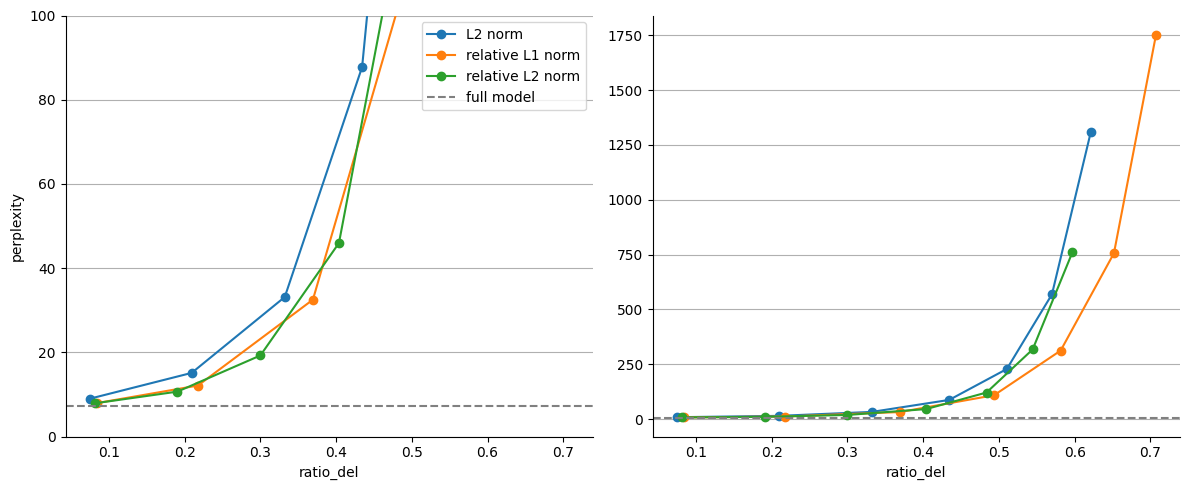

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# axes[0].plot(results_threshold_except["ratio_del", 'L1'], results_threshold_except["perplexity", 'L1'],
#              marker='o', label="L1 norm")
axes[0].plot(results_threshold_except["ratio_del", 'L2'], results_threshold_except["perplexity", 'L2'],
             marker='o', label="L2 norm")
axes[0].plot(results_threshold_rel_except["ratio_del", 'L1'], results_threshold_rel_except["perplexity", 'L1'],
             marker='o', label="relative L1 norm")
axes[0].plot(results_threshold_rel_except["ratio_del", 'L2'], results_threshold_rel_except["perplexity", 'L2'],
             marker='o', label="relative L2 norm")
axes[0].axhline(results.loc[0, 'perplexity'], c='gray', linestyle='--', label='full model')

axes[0].set_ylim(0, 100)
axes[0].set_xlabel("ratio_del")
axes[0].set_ylabel("perplexity")
axes[0].legend()
axes[0].grid(axis='y')

# axes[1].plot(results_threshold_except["ratio_del", 'L1'], results_threshold_except["perplexity", 'L1'],
#              marker='o', label="L1 norm")
axes[1].plot(results_threshold_except["ratio_del", 'L2'], results_threshold_except["perplexity", 'L2'],
             marker='o', label="L2 norm")
axes[1].plot(results_threshold_rel_except["ratio_del", 'L1'], results_threshold_rel_except["perplexity", 'L1'],
             marker='o', label="relative L1 norm")
axes[1].plot(results_threshold_rel_except["ratio_del", 'L2'], results_threshold_rel_except["perplexity", 'L2'],
             marker='o', label="relative L2 norm")
axes[1].axhline(results.loc[0, 'perplexity'], c='gray', linestyle='--', label='full model')

axes[1].set_xlabel("ratio_del")
axes[1].grid(axis='y')

sns.despine()
plt.tight_layout()
plt.show()

## Using weighted relative norm

In [57]:
@torch.no_grad()
def undo_small_rel_changes(model):
    def hook_threshold(module, inps, outs):
        # weighting outputs by neuron importance
        token_norms = norm_function(inps[0].abs(), outs.abs() * module.grad_imp.to(DEV))
        mask = token_norms >= get_threshold(module)
        ratio_over_thr.append(mask.sum().item() / mask.numel())
        return outs * mask

    use_cache = model.config.use_cache
    model.config.use_cache = False
    gc.collect()
    torch.cuda.empty_cache()

    index = pd.MultiIndex(levels=[[], []], codes=[[], []], names=['norm_type', 'threshold'])
    results_threshold_rel = pd.DataFrame(columns=['perplexity', 'ratio_del'], index=index)

    norm_types = ('L1', 'L2', 'max')
    for q in range(10, 71, 10):
        print(f'percentile {q}')
        q /= 100
        # set thresholds for each layer
        for i, layer in enumerate(model.model.layers):
            mlp = layer.mlp
            mlp.threshold_w_rel_L1 = mlp.w_rel_thresholds_L1[q]
            mlp.threshold_w_rel_L2 = mlp.w_rel_thresholds_L2[q]
            mlp.threshold_w_rel_max = mlp.w_rel_thresholds_max[q]

        for norm_type, norm_function, get_threshold in zip(
                norm_types,
                (rel_L1_norm, rel_L2_norm, rel_max_norm),
                (get_w_rel_L1_threshold, get_w_rel_L2_threshold, get_w_rel_max_threshold)):
            # register hooks
            hooks = []
            ratio_over_thr = []
            for i, layer in enumerate(model.model.layers):
                if i in layers_to_keep:
                    ratio_over_thr.append(1)
                    continue
                mlp = layer.mlp
                h = mlp.register_forward_hook(hook_threshold)
                hooks.append(h)
            # evaluate
            ppl = eval_ppl(model, wiki_testloader, device=DEV)
            ratio_del = 1 - np.mean(ratio_over_thr)
            # save results
            print(f'{norm_type} norm\t\t--> deleted ratio {ratio_del*100:.6f}, ppl {ppl:.6f}')
            results_threshold_rel.loc[(norm_type, q*100), :] = [ppl, ratio_del]

            for h in hooks:
                h.remove()

        print()

    model.config.use_cache = use_cache
    return results_threshold_rel

results_threshold_w_rel_except = undo_small_rel_changes(model)
results_threshold_w_rel_except = results_threshold_w_rel_except.unstack(level=0)
results_threshold_w_rel_except.to_csv('results_threshold_w_rel_except.csv')

percentile 10
L1 norm		--> deleted ratio 9.281679, ppl 8.081093
L2 norm		--> deleted ratio 9.675747, ppl 8.122149
max norm		--> deleted ratio 10.830407, ppl 9.003696

percentile 20
L1 norm		--> deleted ratio 22.490000, ppl 12.239218
L2 norm		--> deleted ratio 19.217091, ppl 10.613427
max norm		--> deleted ratio 18.616693, ppl 12.437208

percentile 30
L1 norm		--> deleted ratio 37.132631, ppl 31.505718
L2 norm		--> deleted ratio 28.101384, ppl 16.448814
max norm		--> deleted ratio 25.172808, ppl 20.324446

percentile 40
L1 norm		--> deleted ratio 48.832648, ppl 100.676147
L2 norm		--> deleted ratio 35.509331, ppl 29.224283
max norm		--> deleted ratio 31.284524, ppl 32.492088

percentile 50
L1 norm		--> deleted ratio 57.191021, ppl 282.711182
L2 norm		--> deleted ratio 41.333352, ppl 55.340973
max norm		--> deleted ratio 37.417649, ppl 60.040359

percentile 60
L1 norm		--> deleted ratio 63.827186, ppl 647.405823
L2 norm		--> deleted ratio 46.270251, ppl 114.709030
max norm		--> deleted r

### Results

In [59]:
results_threshold_w_rel_except

perplexity                         ratio_del                    
norm_type           L1          L2         max        L1        L2       max
threshold                                                                   
10.0          8.081093    8.122149    9.003696  0.092817  0.096757  0.108304
20.0         12.239218   10.613427   12.437208    0.2249  0.192171  0.186167
30.0         31.505718   16.448814   20.324446  0.371326  0.281014  0.251728
40.0        100.676147   29.224283   32.492088  0.488326  0.355093  0.312845
50.0        282.711182   55.340973   60.040359   0.57191  0.413334  0.374176
60.0        647.405823   114.70903  139.774994  0.638272  0.462703  0.443421
70.0       1244.749268  258.064545  540.813599  0.694848  0.511458  0.527095

#### Norm type comparison

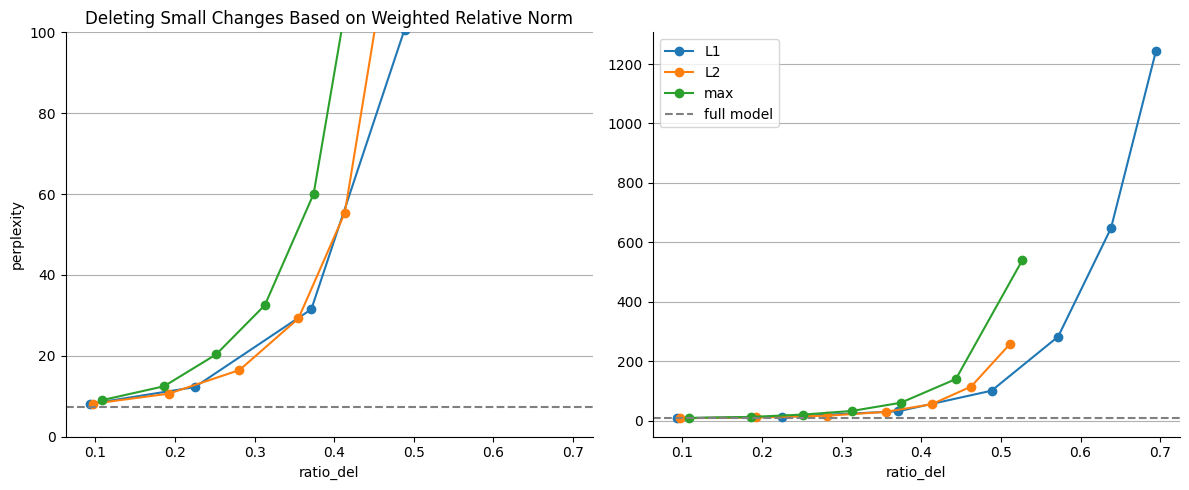

In [62]:
norm_types = ["L1", "L2", "max"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for norm in norm_types:
    axes[0].plot(results_threshold_w_rel_except["ratio_del", norm],
                 results_threshold_w_rel_except["perplexity", norm],
                 marker='o', label=norm)
axes[0].axhline(results.loc[0, 'perplexity'], c='gray', linestyle='--', label='full model')
axes[0].set_title("Deleting Small Changes Based on Weighted Relative Norm")
axes[0].set_xlabel("ratio_del")
axes[0].set_ylabel("perplexity")
axes[0].set_ylim(0, 100)
# axes[0].legend()
axes[0].grid(axis='y')

for norm in norm_types:
    axes[1].plot(results_threshold_w_rel_except["ratio_del", norm],
                 results_threshold_w_rel_except["perplexity", norm],
                 marker='o', label=norm)
axes[1].axhline(results.loc[0, 'perplexity'], c='gray', linestyle='--', label='full model')
axes[1].set_xlabel("ratio_del")
axes[1].legend()
axes[1].grid(axis='y')

sns.despine()
plt.tight_layout()
plt.show()


#### Relative vs. weighted relative norm

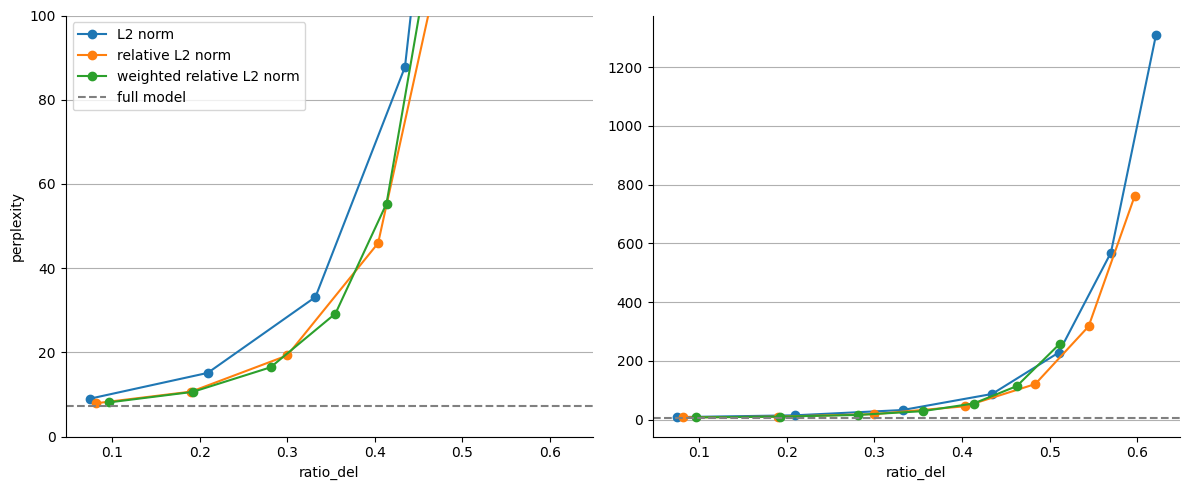

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(results_threshold_except["ratio_del", 'L2'], results_threshold_except["perplexity", 'L2'],
             marker='o', label="L2 norm")
axes[0].plot(results_threshold_rel_except["ratio_del", 'L2'], results_threshold_rel_except["perplexity", 'L2'],
             marker='o', label="relative L2 norm")
axes[0].plot(results_threshold_w_rel_except["ratio_del", 'L2'], results_threshold_w_rel_except["perplexity", 'L2'],
             marker='o', label="weighted relative L2 norm")

axes[0].axhline(results.loc[0, 'perplexity'], c='gray', linestyle='--', label='full model')

axes[0].set_ylim(0, 100)
axes[0].set_xlabel("ratio_del")
axes[0].set_ylabel("perplexity")
axes[0].legend()
axes[0].grid(axis='y')


axes[1].plot(results_threshold_except["ratio_del", 'L2'], results_threshold_except["perplexity", 'L2'],
             marker='o', label="L2 norm")
axes[1].plot(results_threshold_rel_except["ratio_del", 'L2'], results_threshold_rel_except["perplexity", 'L2'],
             marker='o', label="relative L2 norm")
axes[1].plot(results_threshold_w_rel_except["ratio_del", 'L2'], results_threshold_w_rel_except["perplexity", 'L2'],
             marker='o', label="weighted relative L2 norm")
# axes[1].plot(results_threshold_w_rel["ratio_del", 'L2'], results_threshold_w_rel["perplexity", 'L2'],
             # marker='o', label="weighted relative L2 norm - no exceptions")
axes[1].axhline(results.loc[0, 'perplexity'], c='gray', linestyle='--', label='full model')

axes[1].set_xlabel("ratio_del")
axes[1].grid(axis='y')

sns.despine()
plt.tight_layout()
plt.show()